# Football Players Stats (2024-2025)
Retrouver toutes les informations sur [Kaggle](https://www.kaggle.com/datasets/hubertsidorowicz/football-players-stats-2024-2025)

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

## Analyse Exploratoire des données

Affichage des premières données

In [3]:

df_players = pd.read_csv("players_data-2024_2025.csv")

df_players.head()

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Att (GK),Thr,Launch%,AvgLen,Opp,Stp,Stp%,#OPA,#OPA/90,AvgDist
0,1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24.0,2000.0,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Max Aarons,eng ENG,"DF,MF",Valencia,es La Liga,24.0,2000.0,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Rodrigo Abajas,es ESP,DF,Valencia,es La Liga,21.0,2003.0,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,James Abankwah,ie IRL,"DF,MF",Udinese,it Serie A,20.0,2004.0,6,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Keyliane Abdallah,fr FRA,FW,Marseille,fr Ligue 1,18.0,2006.0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df_players.shape

(2854, 267)

### Quelques Satistiques descriptives

Un peu de définition :

- GK (Goalkeeper) → Gardien de but
- DF (Defender) → Défenseur
- MF (Midfielder) → Milieu de terrain
- FW (Forward) → Attaquant

In [5]:
df_players['Pos'].value_counts()

Pos
DF       859
MF       589
FW       371
FW,MF    325
MF,FW    230
GK       212
DF,MF    110
MF,DF     81
DF,FW     53
FW,DF     24
Name: count, dtype: int64

On simplifie la colonne concernant le poste du joueur.

In [6]:
df_players['Primary_Pos'] = df_players['Pos'].str.split(',').str[0]
df_players['Primary_Pos'].value_counts()

/var/folders/tv/6w35m7px2gnf01qr08f7v8040000gn/T/ipykernel_46046/3040849893.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_players['Primary_Pos'] = df_players['Pos'].str.split(',').str[0]


Primary_Pos
DF    1022
MF     900
FW     720
GK     212
Name: count, dtype: int64

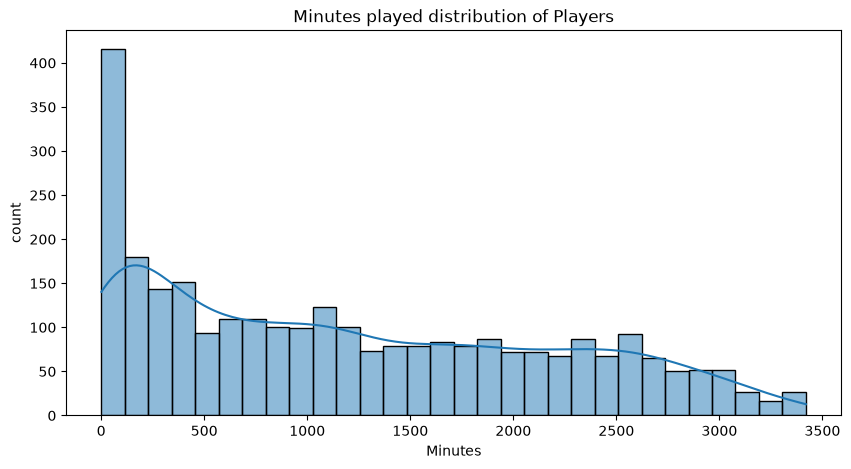

In [7]:
plt.figure(figsize=(10,5))
sns.histplot(df_players['Min'], bins=30, kde=True)
plt.title("Minutes played distribution of Players")
plt.xlabel("Minutes")
plt.ylabel("count")
plt.show()

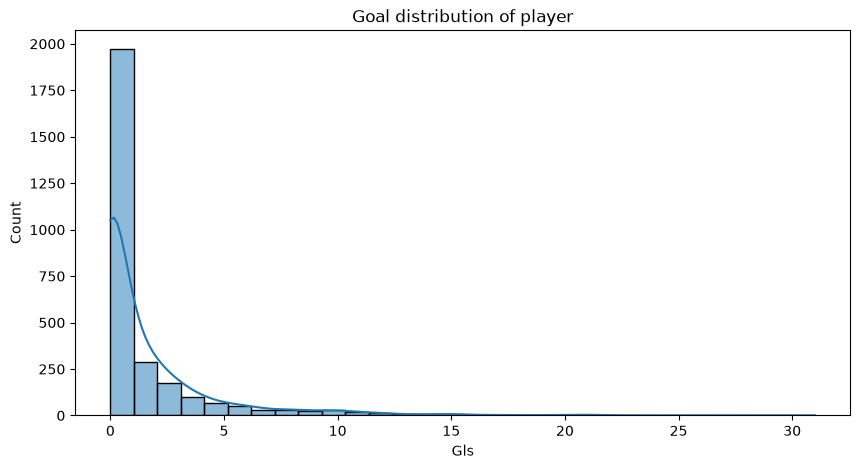

In [8]:
plt.figure(figsize=(10,5))
sns.histplot(df_players["Gls"], bins=30, kde=True)
plt.title("Goal distribution of player")
plt.show()

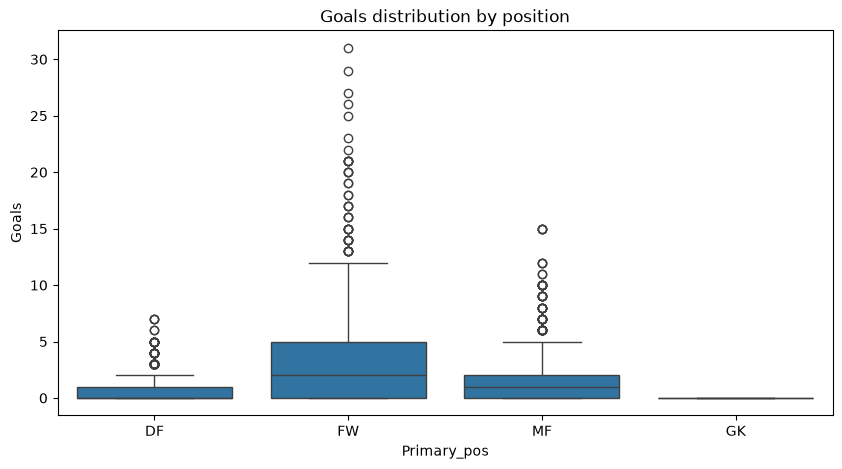

In [9]:
plt.figure(figsize=(10,5))
sns.boxplot(x='Primary_Pos', y='Gls', data=df_players)
plt.title("Goals distribution by position")
plt.xlabel("Primary_pos")
plt.ylabel("Goals")
plt.show()

## Analyse des corrélations et Sélection de variables.

Nous allons nous intéresser qu'à un sous ensemble des données. Voici leurs définitions pour mieux s'y retrouver.

**Statistiques de temps de jeu**:
- MP – Matches Played (Matchs joués): Nombre total de matchs disputés par le joueur.
- Starts – Matches Started (Titularisations): Nombre de matchs commencés dans le onze de départ.
- Min – Minutes Played (Minutes jouées): Nombre total de minutes disputées.
- 90s – Equivalent en matchs complets: Nombre de matchs complets équivalents disputés. Elle permet de comparer équitablement des joueurs qui n'ont pas le même temps de jeu.

**Statistiques offensives**:
- Gls – Goals (Buts): Nombre total de buts marqués.
- Ast – Assists (Passes décisives): Nombre de passes ayant conduit directement à un but.
- G+A – Goals + Assists: Somme des buts et des passes décisives.
- G-PK – Non-Penalty Goals (Buts hors penalty): Nombre de buts marqués en excluant les penaltys.
- xG – Expected Goals (Buts attendus): Mesure le nombre de buts qu'un joueur aurait dû marquer compte tenu de la qualité de ses occasions.
- xAG – Expected Assisted Goals: C'est une mesure de la qualité des occasions qu'un joueur crée pour ses coéquipiers.
- npxG – Non-Penalty Expected Goals: Expected Goals sans les penaltys.

**Statistiques Défensives**:
- Tkl – Total Tackles (Tacles tentés): Nombre total de tacles effectués par un joueur.
- TklW – Tackles Won (Tacles réussis): Nombre de tacles ayant permis de récupérer effectivement le ballon ou de stopper l'action adverse.
- Blocks – Contres / Blocages: Nombre de tirs ou de passes bloqués.
- Int – Interceptions: Nombre de passes adverses interceptées.
- Tkl+Int – Tackles + Interceptions: Addition des tacles et interceptions.
- Clr – Clearances (Dégagements): Nombre de ballons dégagés loin de sa propre zone de but.
- Err – Errors Leading to Goals (Erreurs menant à un but): Nombre d'erreurs individuelles ayant conduit directement à un but adverse.

**Statistiques de créativité sur les passes**:

- PrgP – Progressive Passes: Nombre de passes qui font significativement avancer le ballon vers le but adverse.
- PrgC - Progressive Carries: Nombre de fois où un joueur fait progresser le ballon par la course ou la conduite.
- Ast_stats_passing – Assists: Nombre de passes ayant directement conduit à un but.
- PPA – Passes into the Penalty Area: Nombre de passes réussies envoyées dans la surface adverse.

**Possession et contrôle du ballon**:
- Touches – Touches de balle: Nombre total de fois où un joueur entre en contact avec le ballon pendant le match.
- Carries – Conduites de balle: Nombre de fois où un joueur déplace le ballon sous son contrôle.
- PrgR – Progressive Runs: Nombre de conduites qui font gagner une distance significative vers le but adverse.
- Mis – Miscontrols (Contrôles ratés): Nombre de fois où un joueur perd momentanément le contrôle du ballon à cause d'une mauvaise première touche ou d'une erreur technique.
- Dis – Dispossessed (Dépossessions): Nombre de fois où un adversaire prend le ballon directement à un joueur.

**Statistiques diverses**:
- CrdY – Yellow Cards (Cartons jaunes): Nombre de cartons jaunes reçus.
- CrdR – Red Cards (Cartons rouges): Nombre de cartons rouges reçus.
- PKwon – Penalties Won (Penaltys obtenus): Nombre de penaltys provoqués pour son équipe.
- PKcon – Penalties Conceded (Penaltys concédés): Nombre de penaltys causés contre son équipe.
- Recov – Ball Recoveries (Récupérations): Nombre de fois où un joueur récupère la possession du ballon pour son équipe.


In [ ]:
# Regroupement des colonnes par catégories
BASIC_PLAYER_INFO = ["Player", "Nation", "Pos", "Squad", "Comp", "Age", "Born"]
PLAYING_TIME_STATS = ["MP", "Starts", "Min", "90s"]
ATTACKING_STATS = ["Gls", "Ast", "G+A", "G-PK", "xG", "xAG", "npxG"]
DEFENSIVE_STATS = ["Tkl", "TklW", "Blocks", "Int", "Tkl+Int", "Clr", "Err"]
PASSING_CREATIVITY_STATS = ["PrgP", "PrgC", "KP", "Ast_stats_passing", "xA", "PPA"]
POSSESSION_BALL_CONTROL_STATS = ["Touches", "Carries", "PrgR", "Mis", "Dis"]
MISCELLANEOUS_STATS = ["CrdY", "CrdR", "PKwon", "PKcon", "Recov"]


In [11]:
# On va s'intéresser uniquement aux joueurs de "champs"
df_players_field = df_players[~df_players["Pos"].isin(["GK"])]

### Satistiques de temps de jeu

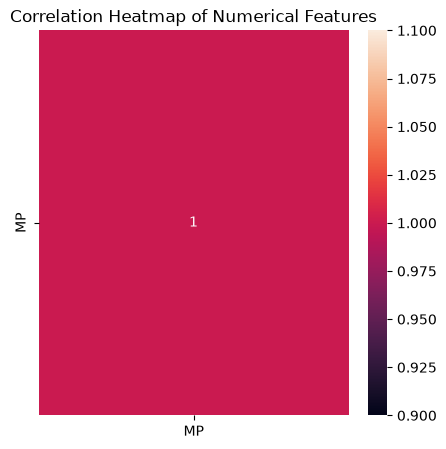

In [12]:
PLAYING_TIME_STATS_NEW = [elem for elem in PLAYING_TIME_STATS if elem not in ["Min", "90s", "Starts"]]

plt.figure(figsize=(5,5))
sns.heatmap(df_players_field[PLAYING_TIME_STATS_NEW].corr(), annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Toutes les variables sur le temps de jeu sont trés corrélées, nous n'en garderont qu'une : MP.

### Statistiques offensives

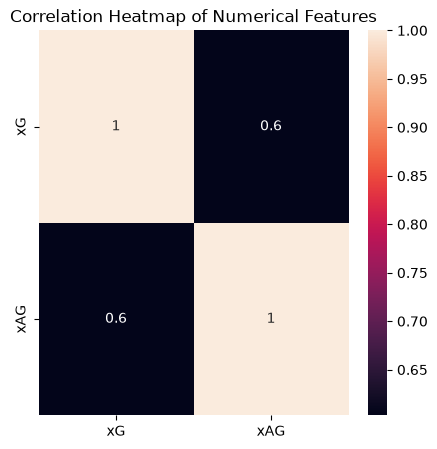

In [13]:
ATTACKING_STATS_NEW = [elem for elem in ATTACKING_STATS if elem not in ["G+A", "Gls", "G-PK", "Ast", "npxG"]]

plt.figure(figsize=(5,5))
sns.heatmap(df_players_field[ATTACKING_STATS_NEW].corr(), annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Beaucoup de variables très corrélées. Nous n'en gardons que deux.

### Statistiques défensives

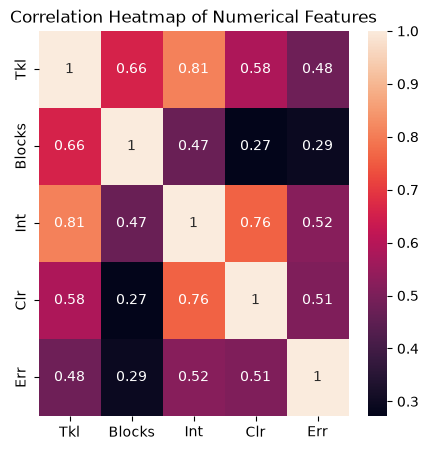

In [14]:
DEFENSIVE_STATS_NEW = [elem for elem in DEFENSIVE_STATS if elem not in ["Tkl+Int", "TklW"]]

plt.figure(figsize=(5,5))
sns.heatmap(df_players_field[DEFENSIVE_STATS_NEW].corr(), annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Nous retirons deux variables corrélées aux autres : "Tkl+Int", "TklW"

### Statistiques de créativité sur les passes

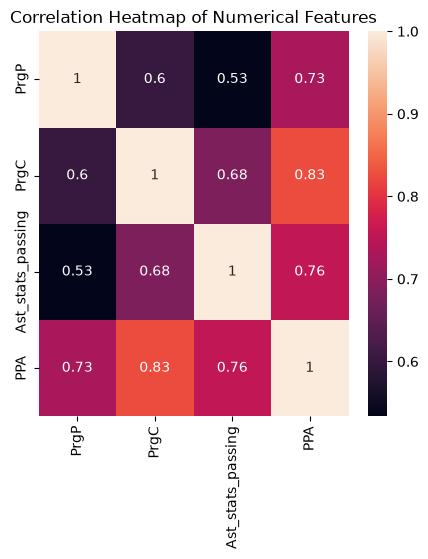

In [15]:
PASSING_CREATIVITY_STATS_NEW = [elem for elem in PASSING_CREATIVITY_STATS if elem not in ["KP", "xA"]]

plt.figure(figsize=(5,5))
sns.heatmap(df_players_field[PASSING_CREATIVITY_STATS_NEW].corr(), annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Deux variables sont retirées.

### Staistiques de possession et contrôle du ballon

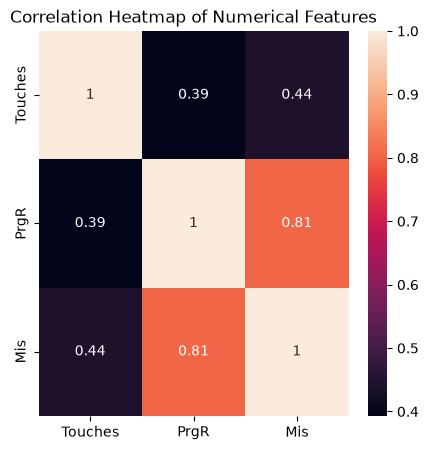

In [16]:
POSSESSION_BALL_CONTROL_STATS_NEW = [elem for elem in POSSESSION_BALL_CONTROL_STATS if elem not in ["Carries", "Dis"]]

plt.figure(figsize=(5,5))
sns.heatmap(df_players_field[POSSESSION_BALL_CONTROL_STATS_NEW].corr(), annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

On retire deux variables, et on accepte une corrélation à 0,81.

### Statistiques diverses

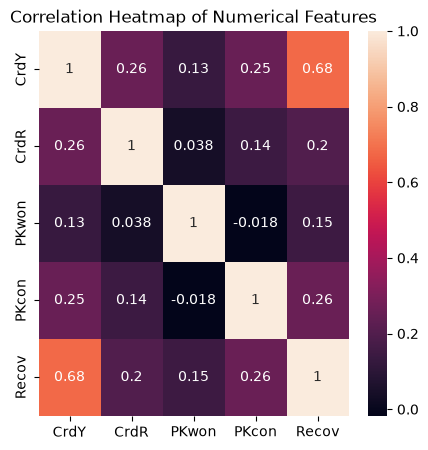

In [17]:
MISCELLANEOUS_STATS_NEW = [elem for elem in MISCELLANEOUS_STATS if elem not in []]

plt.figure(figsize=(5,5))
sns.heatmap(df_players_field[MISCELLANEOUS_STATS_NEW].corr(), annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Aucune variable corrélée.

### Sélection des variables

In [18]:
FEATURES_SELECTED = PLAYING_TIME_STATS_NEW + ATTACKING_STATS_NEW \
    + DEFENSIVE_STATS_NEW + PASSING_CREATIVITY_STATS_NEW \
    + POSSESSION_BALL_CONTROL_STATS_NEW + MISCELLANEOUS_STATS_NEW

df_selected = df_players_field[FEATURES_SELECTED]

In [19]:
df_selected.shape

(2642, 20)

## Modélisation Isolation Forest

In [36]:
from sklearn.ensemble import IsolationForest

# Définition de l'Isolation Forest.
isolation_forest = IsolationForest(n_estimators=100, max_samples=128, n_jobs=-1, random_state=42)

# Entaînement du modèle Isolation Forest sur les données sélectionnées.
isolation_forest.fit(df_selected)

# Calcul du score d'anomalie pour chaque joueur.
anomaly_score_if = -isolation_forest.decision_function(df_selected)
df_players_field["anomaly_score_if"] = anomaly_score_if

In [37]:
# Top 15 players with the highest anomaly scores
df_players_field.sort_values(by="anomaly_score_if", ascending=False)[BASIC_PLAYER_INFO+["anomaly_score_if"]].head(15)

,Player,Nation,Pos,Squad,Comp,Age,Born,anomaly_score_if
2304,Mohamed Salah,eg EGY,FW,Liverpool,eng Premier League,32.0,1992.0,0.211077
2792,Lamine Yamal,es ESP,FW,Barcelona,es La Liga,17.0,2007.0,0.190302
1691,Kylian Mbappé,fr FRA,FW,Real Madrid,es La Liga,25.0,1998.0,0.185791
891,Bruno Fernandes,pt POR,MF,Manchester Utd,eng Premier League,29.0,1994.0,0.176799
1289,Vinicius Júnior,br BRA,FW,Real Madrid,es La Liga,24.0,2000.0,0.153499
1693,Bryan Mbeumo,cm CMR,FW,Brentford,eng Premier League,24.0,1999.0,0.153456
434,Moisés Caicedo,ec ECU,"MF,DF",Chelsea,eng Premier League,22.0,2001.0,0.151174
2245,Morgan Rogers,eng ENG,"FW,MF",Aston Villa,eng Premier League,22.0,2002.0,0.150042
2393,Antoine Semenyo,gh GHA,FW,Bournemouth,eng Premier League,24.0,2000.0,0.147604
1960,Michael Olise,fr FRA,"FW,MF",Bayern Munich,de Bundesliga,22.0,2001.0,0.144247


En comparant avec les notes de [EA Sport FC 26](https://www.kaggle.com/datasets/justdhia/ea-sports-fc-26-player-ratings), on remarque que dans notre top 15, on voit apparaître les joueurs les mieux notés (comme par exemple Mohamed Salah et Kylian Mbappé qui ont la meilleure note). On remarque également la présence d'un joueur très mal noté Moisés Caicedo. 

## Visualisation et compréhension des anomalies

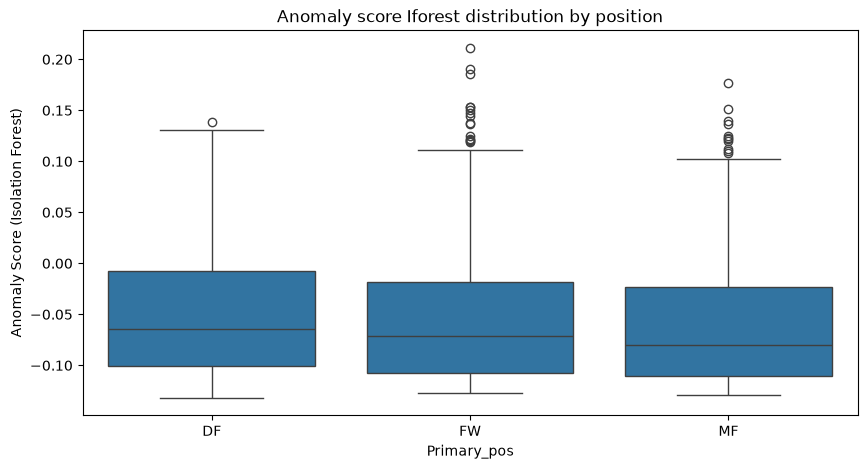

In [22]:
plt.figure(figsize=(10,5))
sns.boxplot(x='Primary_Pos', y='anomaly_score_if', data=df_players_field)
plt.title("Anomaly score Iforest distribution by position")
plt.xlabel("Primary_pos")
plt.ylabel("Anomaly Score (Isolation Forest)")
plt.show()

Les "défenseurs" ont en moyenne un score d'anomalies plus élevées. Cependant, les plus grandes valeurs d'anomalies concernent les milieu et les attaquants.

In [23]:
# Collect index and name of the top 15 players with the highest anomaly score according to Isolation Forest & LOF
top15_anomalies = df_players_field\
    .sort_values(by="anomaly_score_if", ascending=False).head(15)

*Justification du choix de l’ACP* : l’Analyse en Composantes Principales (ACP) permet de réduire la dimensionnalité du jeu de données, facilitant ainsi sa visualisation et son interprétation. De plus, l’ACP conserve en priorité les directions présentant la plus forte variance. Or, les observations atypiques se caractérisent souvent par des valeurs extrêmes qui augmentent la dispersion des données. En préservant cette variance, l’ACP tend donc à maintenir la séparation entre les points aberrants et les observations normales, facilitant leur identification.

In [24]:
def plot_pca_results(pca_columns, title):
    df_players_pca = df_players_field.copy()
    
    pca = PCA(n_components=2)
    
    # Variables quantitatives
    X = df_players_pca[pca_columns].fillna(-1)
    # Centrage-réduction
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    data_pca = pca.fit_transform(X_scaled)
    
    print(f"Explained variance ratio: {np.sum(pca.explained_variance_ratio_)}")

    df_players_pca['pca_defense_1'] = data_pca[:, 0]
    df_players_pca['pca_defense_2'] = data_pca[:, 1]


    # Plotting the PCA results
    plt.figure(figsize=(12, 10))
    plt.scatter(df_players_pca[df_players_pca['Primary_Pos'] == 'DF']['pca_defense_1'], 
                df_players_pca[df_players_pca['Primary_Pos'] == 'DF']['pca_defense_2'], 
                color='blue', label='Défenseur', alpha=0.3)
    plt.scatter(df_players_pca[df_players_pca['Primary_Pos'] == 'MF']['pca_defense_1'], 
                df_players_pca[df_players_pca['Primary_Pos'] == 'MF']['pca_defense_2'], 
                color='red', label='Milieu', alpha=0.3)
    plt.scatter(df_players_pca[df_players_pca['Primary_Pos'] == 'FW']['pca_defense_1'], 
                df_players_pca[df_players_pca['Primary_Pos'] == 'FW']['pca_defense_2'], 
                color='green', label='Attaquant', alpha=0.3)

    
    # Annotation for the top 15 anomalies
    for index, row in top15_anomalies.iterrows():
        player_name = row['Player']
        player_data = df_players_pca[df_players_pca['Player'] == player_name]
        player_pos = player_data['Primary_Pos'].values[0]
        plt.annotate(player_name, 
                    (player_data['pca_defense_1'].values[0], player_data['pca_defense_2'].values[0]), 
                    textcoords="offset points", 
                    xytext=(0,10), 
                    ha='center', 
                    fontsize=9, 
                    color='green' if player_pos == 'FW' else 'red' if player_pos == 'MF' else 'blue', 
                    weight='bold')


    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title(title)
    plt.legend()
    plt.show()

### Toutes les variables sélectionnées.

Explained variance ratio: 0.669514188663705


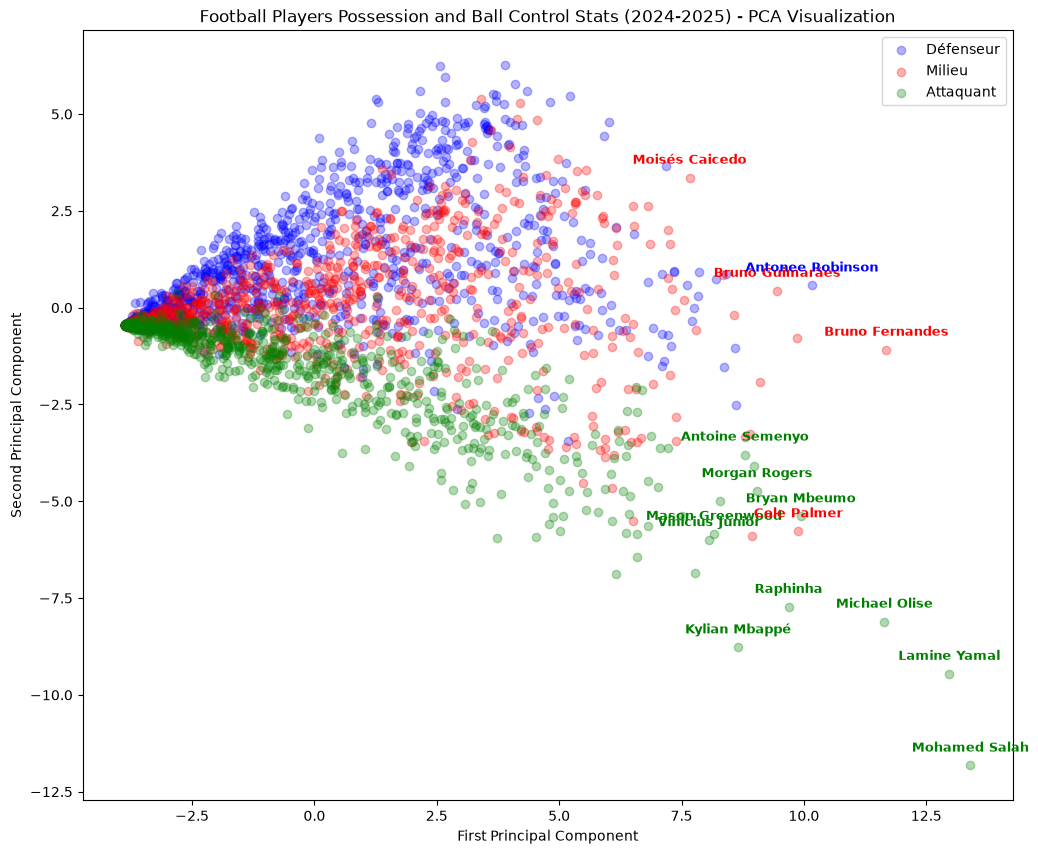

In [25]:
title = 'Football Players Possession and Ball Control Stats (2024-2025) - PCA Visualization'
pca_columns = FEATURES_SELECTED 

plot_pca_results(pca_columns, title)

Avec 66% de la variance expliquée, certains joueurs comme Salah ou Yamal par exemple se distinguent très nettement des autres points.

### Statistiques Offensives

Explained variance ratio: 1.0


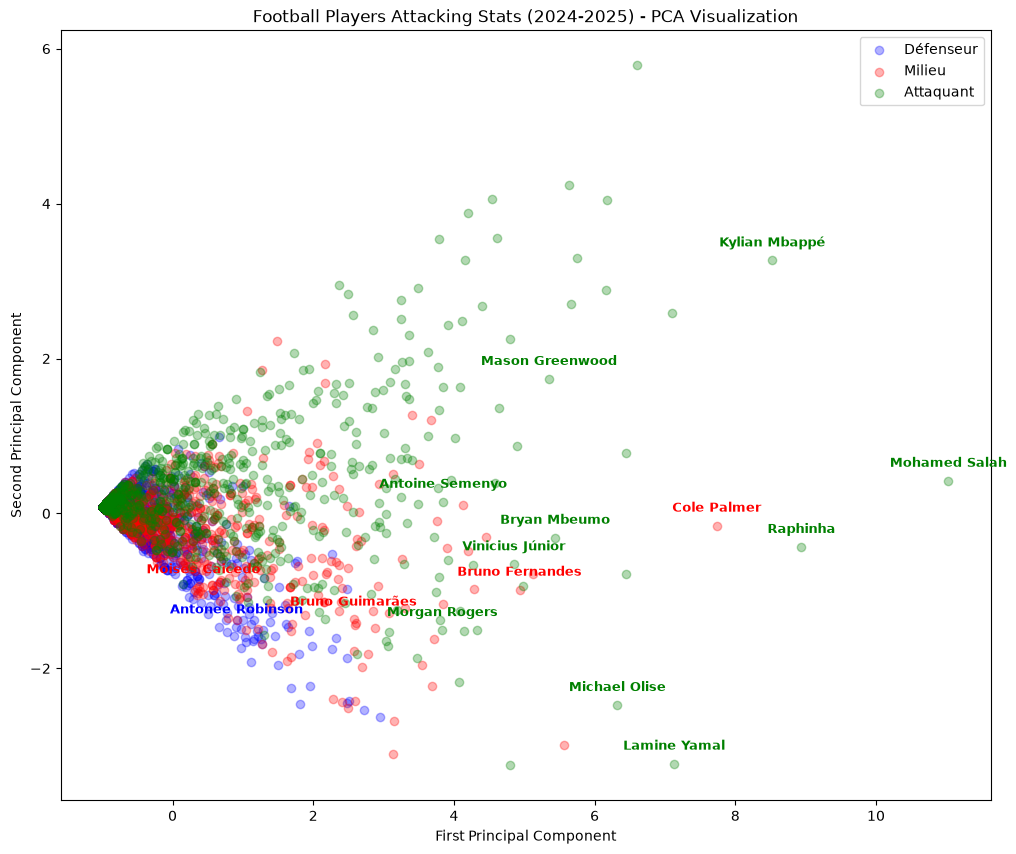

In [26]:
title = 'Football Players Attacking Stats (2024-2025) - PCA Visualization'
pca_columns = ATTACKING_STATS_NEW

plot_pca_results(pca_columns, title)

Les statistiques offensives concernent uniquement les informations sur le nombre de but et le nombre de passes décisives. A ce jeu là, les meilleures joueurs du monde offensifs sont facile à distinguer.

In [27]:
top15_anomalies[BASIC_PLAYER_INFO + ATTACKING_STATS_NEW]

,Player,Nation,Pos,Squad,Comp,Age,Born,xG,xAG
2304,Mohamed Salah,eg EGY,FW,Liverpool,eng Premier League,32.0,1992.0,25.2,14.2
2792,Lamine Yamal,es ESP,FW,Barcelona,es La Liga,17.0,2007.0,9.8,13.9
1691,Kylian Mbappé,fr FRA,FW,Real Madrid,es La Liga,25.0,1998.0,25.9,7.7
891,Bruno Fernandes,pt POR,MF,Manchester Utd,eng Premier League,29.0,1994.0,9.9,8.5
1289,Vinicius Júnior,br BRA,FW,Real Madrid,es La Liga,24.0,2000.0,10.4,8.0
1693,Bryan Mbeumo,cm CMR,FW,Brentford,eng Premier League,24.0,1999.0,12.3,8.3
434,Moisés Caicedo,ec ECU,"MF,DF",Chelsea,eng Premier League,22.0,2001.0,0.8,3.0
2245,Morgan Rogers,eng ENG,"FW,MF",Aston Villa,eng Premier League,22.0,2002.0,6.6,7.8
2393,Antoine Semenyo,gh GHA,FW,Bournemouth,eng Premier League,24.0,2000.0,10.0,5.8
1960,Michael Olise,fr FRA,"FW,MF",Bayern Munich,de Bundesliga,22.0,2001.0,9.7,12.0


In [28]:
df_players_field[ATTACKING_STATS_NEW].describe()

,xG,xAG
count,2642.000000,2642.000000
mean,1.843717,1.307986
std,2.885155,1.719404
min,0.000000,0.000000
25%,0.200000,0.100000
50%,0.800000,0.700000
75%,2.300000,1.800000
max,27.100000,14.200000


En regardant plus précisemment Mohamed Salah, il fait partie des meilleurs buteurs et est le meilleur passeur sur la saison.

### Statistiques de créativité sur les passes.

Explained variance ratio: 0.8881689559631303


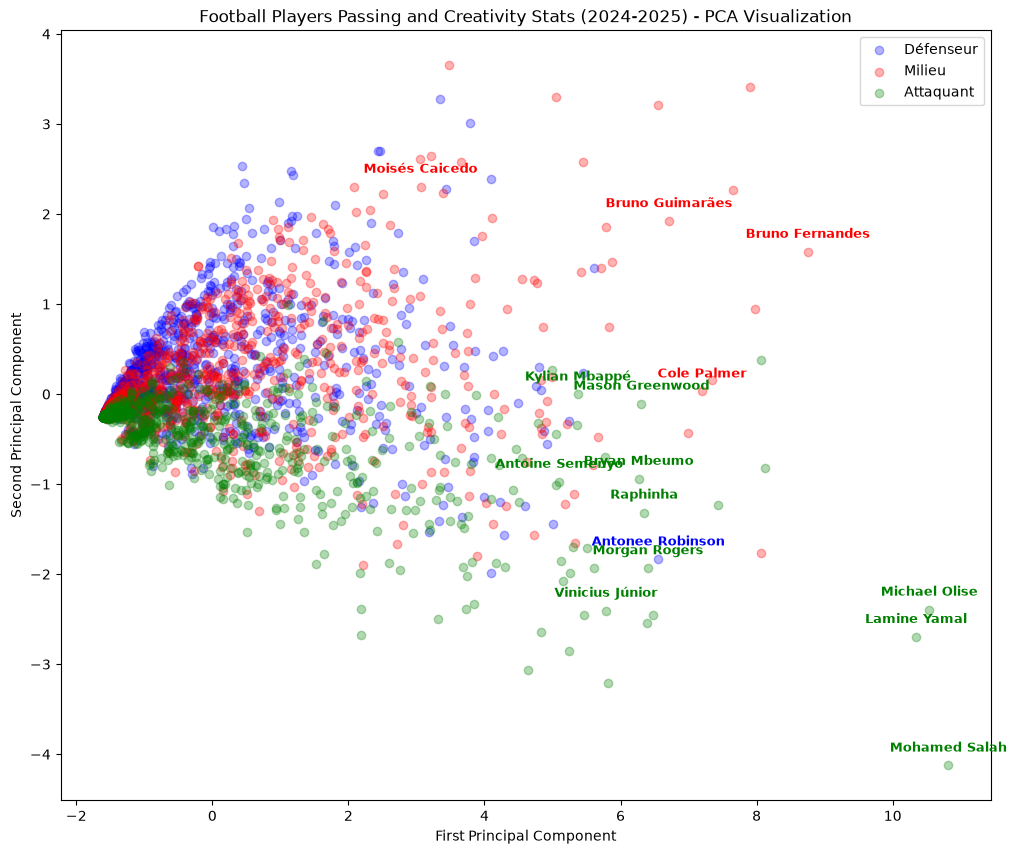

In [29]:
title = 'Football Players Passing and Creativity Stats (2024-2025) - PCA Visualization'
pca_columns = PASSING_CREATIVITY_STATS_NEW

plot_pca_results(pca_columns, title)

Sur ce type de données, quelques attaquants se distinguent encore plus des autres. De plus, certains milieux comme Bruno Fernandes se démarquent également.

In [30]:
top15_anomalies[BASIC_PLAYER_INFO + PASSING_CREATIVITY_STATS_NEW]

,Player,Nation,Pos,Squad,Comp,Age,Born,PrgP,PrgC,Ast_stats_passing,PPA
2304,Mohamed Salah,eg EGY,FW,Liverpool,eng Premier League,32.0,1992.0,144,154,18,93
2792,Lamine Yamal,es ESP,FW,Barcelona,es La Liga,17.0,2007.0,160,181,13,95
1691,Kylian Mbappé,fr FRA,FW,Real Madrid,es La Liga,25.0,1998.0,140,150,3,52
891,Bruno Fernandes,pt POR,MF,Manchester Utd,eng Premier League,29.0,1994.0,325,77,10,85
1289,Vinicius Júnior,br BRA,FW,Real Madrid,es La Liga,24.0,2000.0,85,169,8,36
1693,Bryan Mbeumo,cm CMR,FW,Brentford,eng Premier League,24.0,1999.0,141,130,7,59
434,Moisés Caicedo,ec ECU,"MF,DF",Chelsea,eng Premier League,22.0,2001.0,215,43,2,34
2245,Morgan Rogers,eng ENG,"FW,MF",Aston Villa,eng Premier League,22.0,2002.0,123,114,10,56
2393,Antoine Semenyo,gh GHA,FW,Bournemouth,eng Premier League,24.0,2000.0,109,140,5,45
1960,Michael Olise,fr FRA,"FW,MF",Bayern Munich,de Bundesliga,22.0,2001.0,184,119,15,111


In [31]:
df_players_field[PASSING_CREATIVITY_STATS_NEW].describe()

,PrgP,PrgC,Ast_stats_passing,PPA
count,2642.000000,2642.000000,2642.000000,2642.000000
mean,48.802044,22.395155,1.290689,10.327025
std,50.435511,27.003874,1.992674,13.139041
min,0.000000,0.000000,0.000000,0.000000
25%,9.000000,3.000000,0.000000,1.000000
50%,34.000000,13.000000,0.000000,6.000000
75%,73.000000,31.000000,2.000000,14.000000
max,362.000000,213.000000,18.000000,111.000000


### Statistiques défensives

Explained variance ratio: 0.8056516748345757


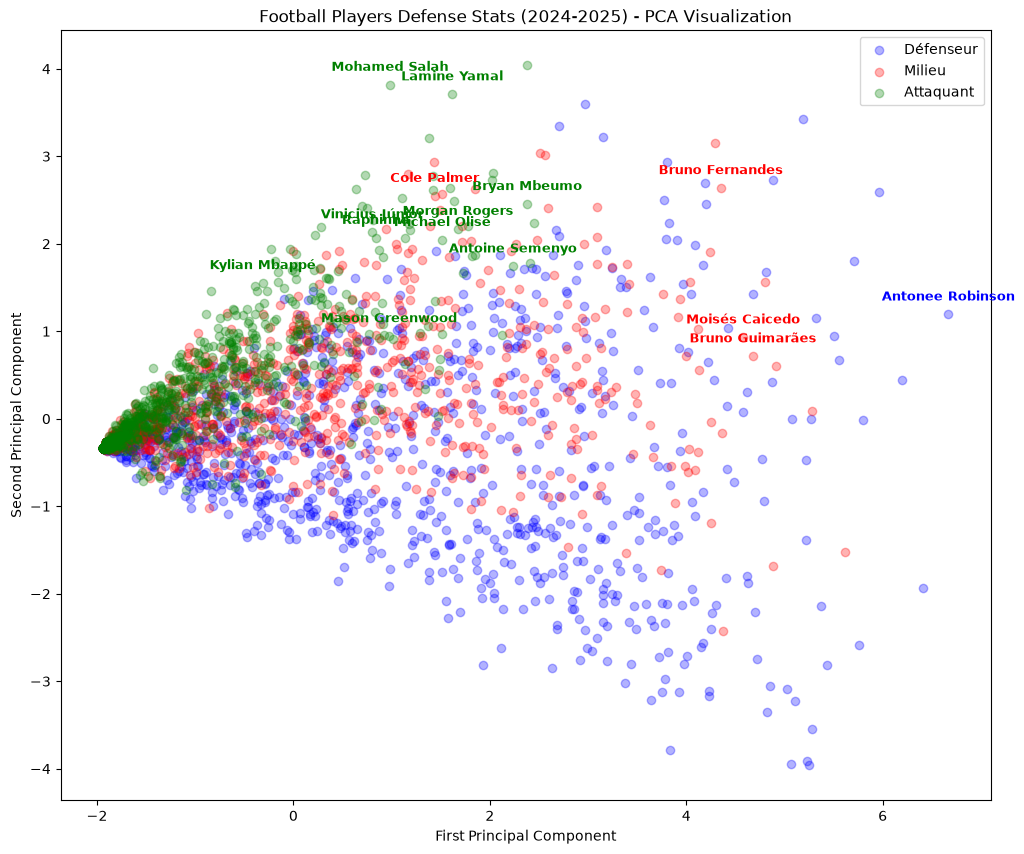

In [32]:
title = 'Football Players Defense Stats (2024-2025) - PCA Visualization'
pca_columns = DEFENSIVE_STATS_NEW

plot_pca_results(pca_columns, title)

In [33]:
top15_anomalies[BASIC_PLAYER_INFO + DEFENSIVE_STATS_NEW]

,Player,Nation,Pos,Squad,Comp,Age,Born,Tkl,Blocks,Int,Clr,Err
2304,Mohamed Salah,eg EGY,FW,Liverpool,eng Premier League,32.0,1992.0,21,62,9,5,0
2792,Lamine Yamal,es ESP,FW,Barcelona,es La Liga,17.0,2007.0,42,57,16,3,0
1691,Kylian Mbappé,fr FRA,FW,Real Madrid,es La Liga,25.0,1998.0,8,33,1,1,1
891,Bruno Fernandes,pt POR,MF,Manchester Utd,eng Premier League,29.0,1994.0,84,55,26,35,3
1289,Vinicius Júnior,br BRA,FW,Real Madrid,es La Liga,24.0,2000.0,21,45,3,1,2
1693,Bryan Mbeumo,cm CMR,FW,Brentford,eng Premier League,24.0,1999.0,49,50,14,55,1
434,Moisés Caicedo,ec ECU,"MF,DF",Chelsea,eng Premier League,22.0,2001.0,114,20,49,60,1
2245,Morgan Rogers,eng ENG,"FW,MF",Aston Villa,eng Premier League,22.0,2002.0,43,45,6,20,2
2393,Antoine Semenyo,gh GHA,FW,Bournemouth,eng Premier League,24.0,2000.0,55,40,11,39,2
1960,Michael Olise,fr FRA,"FW,MF",Bayern Munich,de Bundesliga,22.0,2001.0,36,44,8,16,2


In [34]:
df_players_field[DEFENSIVE_STATS_NEW].describe()

,Tkl,Blocks,Int,Clr,Err
count,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000
mean,21.831188,11.433762,10.776306,30.956094,0.722937
std,20.679454,11.625171,11.843240,40.737126,1.163497
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,2.000000,2.000000,4.000000,0.000000
50%,16.000000,8.000000,7.000000,15.000000,0.000000
75%,34.000000,17.000000,16.000000,42.000000,1.000000
max,133.000000,75.000000,72.000000,249.000000,9.000000


### "Meilleur" combinaison permettant de distinguers nos "anomalies"

Explained variance ratio: 0.6586059606302287


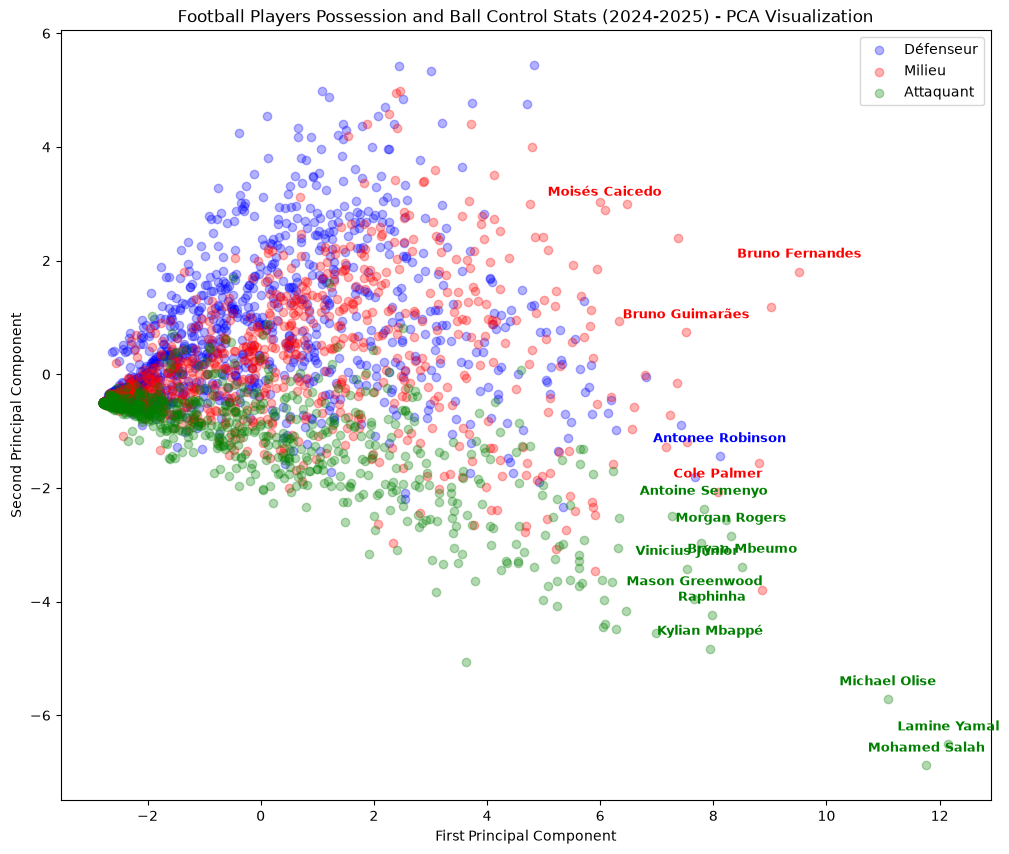

In [35]:
title = 'Football Players Possession and Ball Control Stats (2024-2025) - PCA Visualization'
pca_columns = POSSESSION_BALL_CONTROL_STATS_NEW + PASSING_CREATIVITY_STATS_NEW + MISCELLANEOUS_STATS_NEW

plot_pca_results(pca_columns, title)

Nos 15 points se distinguent très fortement des autres sur ces différentes caractéristiques.